# KAPPA 001 — Dataset exploration and baseline

Complete audit of the RSNA Knee Abnormality Detection dataset. This is the
reference document for the project: it establishes what the data *is*, closes the
open questions in [`overview.md` §5](../overview.md), and leaves behind reusable
code (a DICOM loader, a submission writer) plus a machine-readable
`audit_summary.json` that later notebooks can assert against.

**Run on Kaggle.** Data mounts read-only at
`/kaggle/input/competitions/rsna-knee-abnormality-detection/` — note the extra
`competitions/` level; the classic `/kaggle/input/<slug>/` path raises
`FileNotFoundError`. Path discovery below handles both. The dataset is ~560 GB,
so a laptop cannot hold it; locally this notebook runs the metadata sections and
skips anything needing pixels.

### Headline findings

| # | Finding | Consequence |
| --- | --- | --- |
| 1 | **Only 58 of 4,407 studies are labelled.** All 4,407 have reports. | Labels must be *derived from report text*. `overview.md` §5.3 has the dependency backwards. |
| 2 | Reports are **train-only** (`test.csv` has one column). | Submitted model is image-only. Closes **Q1**. |
| 3 | Reports span **7+ languages**. | English radiology encoders (RadBERT, BioClinicalBERT) are unusable. |
| 4 | Series are **16-22 slices, ~12x anisotropic, with inter-slice gaps**. | Isotropic 3D is mostly interpolation. **2.5D is the baseline.** |
| 5 | `Fluid_Sensitive` and `Fat_Suppression` are **byte-identical**. | One contrast bit, not two. |
| 6 | `Laterality` missing on roughly half of studies. | Left/right canonicalisation needs a fallback or must be dropped. |
| 7 | Plane and contrast are **given in metadata**. | No DICOM-tag sequence taxonomy needed. Closes **Q3**. |

### Contents

1. Setup and path discovery
2. Inventory and scale
3. Submission contract
4. Labels — missingness, prevalence, co-occurrence
5. Reports — availability, language, structure, weak-label feasibility
6. Series and sequence taxonomy
7. DICOM geometry — the input-representation decision
8. Acquisition metadata — patient linkage, laterality, scanners
9. Pixel data — reusable loader, montages, intensity
10. Baseline submission
11. Audit summary
12. Where this leaves the project

## 1. Setup and path discovery

In [18]:
import glob
import json
import os
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

warnings.filterwarnings("ignore")
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
})
BLUE, GREY, RED = "#4477AA", "#BBBBBB", "#CC6677"

# Fixed submission order, hard-coded. Never derive this by slicing columns or
# splitting a string: "Baker's" contains an apostrophe (overview.md section 2).
LABELS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA",
    "Effusion", "Synovitis", "Baker's",
    "Contusion", "Fracture",
]
assert len(LABELS) == 12
SUBMISSION_HEADER = "StudyInstanceUID," + ",".join(LABELS)
SENTINEL = "train.csv"


def find_data_root() -> Path:
    """Locate the competition files. Discovers the layout instead of assuming it."""
    for root in (Path("/kaggle/input/competitions/rsna-knee-abnormality-detection"),
                 Path("/kaggle/input/rsna-knee-abnormality-detection")):
        if (root / SENTINEL).is_file():
            return root
    hits = glob.glob(f"/kaggle/input/**/{SENTINEL}", recursive=True)
    if hits:
        return Path(hits[0]).parent
    try:
        from kappa.data.paths import raw_dir
        if (raw_dir() / SENTINEL).is_file():
            return raw_dir()
    except Exception:
        pass
    for base in (Path.cwd(), *Path.cwd().parents[:3]):
        for sub in (base, base / "data" / "raw", base / "data" / "interim"):
            if (sub / SENTINEL).is_file():
                return sub
    raise FileNotFoundError(
        f"could not find {SENTINEL}. On Kaggle use '+ Add Input' to attach the "
        "competition; locally run `make data`."
    )


DATA = find_data_root()
ON_KAGGLE = str(DATA).startswith("/kaggle")
OUT = Path("/kaggle/working") if ON_KAGGLE else Path.cwd()
findings = {}

print(f"data root : {DATA}")
print(f"on kaggle : {ON_KAGGLE}")
print(f"outputs   : {OUT}")

data root : /kaggle/input/competitions/rsna-knee-abnormality-detection
on kaggle : True
outputs   : /kaggle/working


## 2. Inventory and scale

In [19]:
entries = sorted(DATA.iterdir())
for p in entries:
    size = f"{p.stat().st_size / 1e6:>9.2f} MB" if p.is_file() else f"{'<dir>':>12}"
    print(f"  {p.name + ('/' if p.is_dir() else ''):26} {size}")

CSVS = {p.stem: p for p in entries if p.suffix == ".csv"}
IMAGE_DIRS = [p for p in entries if p.is_dir()]
TRAIN_IMAGES = next((p for p in IMAGE_DIRS if p.name.startswith("train")), None)
TEST_IMAGES = next((p for p in IMAGE_DIRS if p.name.startswith("test")), None)

train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
series = pd.read_csv(DATA / "train_series.csv")
test_series = pd.read_csv(DATA / "test_series.csv")
sample_sub = pd.read_csv(DATA / "sample_submission.csv")

print(f"\ntrain.csv        {train.shape}")
print(f"train_series.csv {series.shape}")
print(f"test.csv         {test.shape}")
print(f"test_series.csv  {test_series.shape}")
print(f"\ntrain columns : {list(train.columns)}")
print(f"series columns: {list(series.columns)}")

findings["n_train_studies"] = int(train["StudyInstanceUID"].nunique())
findings["n_train_series"] = int(len(series))
findings["n_public_test_studies"] = int(len(test))

  sample_submission.csv           0.00 MB
  test.csv                        0.00 MB
  test_series/                      <dir>
  test_series.csv                 0.00 MB
  train.csv                       5.69 MB
  train_series/                     <dir>
  train_series.csv                3.46 MB

train.csv        (4407, 14)
train_series.csv (24371, 5)
test.csv         (3, 1)
test_series.csv  (15, 5)

train columns : ['StudyInstanceUID', 'Report', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']
series columns: ['StudyInstanceUID', 'SeriesInstanceUID', 'Fluid_Sensitive', 'Fat_Suppression', 'Anatomical_Plane']


### What counts as one "image"

The hierarchy matters, because "dataset size" is ambiguous here. These are **MRI
volumes, not radiographs**:

```
Study   = one knee examination  = one submission row  = one label vector
  └── Series (3-14 per study)   = one pulse sequence in one plane
        └── Slice (16-22 each)  = one .dcm file, one 2D image
```

Prediction and labelling happen at **study** level. Model input is a series or a
stack of slices. The counts below are reported at all three levels.

### Label glossary

| # | Column | Group | Clinical meaning |
| --- | --- | --- | --- |
| 1 | `ACL` | Ligament | Anterior cruciate ligament tear |
| 2 | `MCL` | Ligament | Medial collateral ligament injury |
| 3 | `Medial Meniscus` | Meniscus | Medial meniscal tear / degeneration |
| 4 | `Lateral Meniscus` | Meniscus | Lateral meniscal tear / degeneration |
| 5 | `Medial OA` | Osteoarthritis | Medial tibiofemoral compartment |
| 6 | `Lateral OA` | Osteoarthritis | Lateral tibiofemoral compartment |
| 7 | `PF OA` | Osteoarthritis | Patellofemoral compartment |
| 8 | `Effusion` | Synovium / fluid | Joint effusion |
| 9 | `Synovitis` | Synovium / fluid | Synovial inflammation |
| 10 | `Baker's` | Synovium / fluid | Baker's (popliteal) cyst |
| 11 | `Contusion` | Bone / trauma | Bone marrow contusion / oedema |
| 12 | `Fracture` | Bone / trauma | Fracture |

All twelve are **independent binary targets** scored by macro-averaged ROC AUC —
one AUC per column, then a plain mean. Each column is worth exactly 1/12,
regardless of how rare it is.

### Train / test split

This is a **Research Code Competition**, so the split is not a simple file
partition:

- `train.csv` — 4,407 studies, with reports, and labels on a small subset.
- `test.csv` — a **3-row placeholder**. The real test set is swapped in when the
  notebook is rescored against the hidden data.
- Scoring is split again into **public** (live leaderboard) and **private**
  (final standing) subsets of that hidden set.

Consequences: never size arrays or batch counts from the public test rows; the
inference path must generalise to an unknown row count; and public-LB movement is
weak evidence compared to cross-validation (`overview.md` §3).

### Missing values across every column

In [20]:
frames = {"train": train, "train_series": series, "test": test,
          "test_series": test_series, "sample_submission": sample_sub}
rows = []
for name, df in frames.items():
    for col in df.columns:
        n_null = int(df[col].isna().sum())
        blank = int((df[col].astype(str).str.strip() == "").sum())
        rows.append({"file": name, "column": col, "rows": len(df),
                     "nulls": n_null, "blank_strings": blank,
                     "missing_%": round((n_null + blank) / len(df) * 100, 1),
                     "n_unique": int(df[col].nunique(dropna=True))})
miss = pd.DataFrame(rows)
print(miss.to_string(index=False))

bad = miss[miss["missing_%"] > 0]
print(f"\ncolumns with any missing data: {len(bad)}")
if len(bad):
    print(bad[["file", "column", "missing_%"]].to_string(index=False))
print("\n>>> Metadata is complete apart from the label columns. Every study has a")
print("    report, a series list, plane and contrast flags. The ONLY missingness")
print("    that matters is the labels -- quantified in section 4.")
findings["columns_with_missing_data"] = int(len(bad))

             file            column  rows  nulls  blank_strings  missing_%  n_unique
            train  StudyInstanceUID  4407      0              0        0.0      4407
            train            Report  4407      0              0        0.0      4276
            train               ACL  4407   4349              0       98.7         2
            train               MCL  4407   4349              0       98.7         2
            train   Medial Meniscus  4407   4349              0       98.7         2
            train  Lateral Meniscus  4407   4349              0       98.7         2
            train         Medial OA  4407   4349              0       98.7         2
            train        Lateral OA  4407   4349              0       98.7         2
            train             PF OA  4407   4349              0       98.7         2
            train          Effusion  4407   4349              0       98.7         2
            train         Synovitis  4407   4349              0  

## 3. Submission contract

In [21]:
checks = {
    "train UIDs unique": bool(train["StudyInstanceUID"].is_unique),
    "test UIDs unique": bool(test["StudyInstanceUID"].is_unique),
    "sample_sub aligns with test.csv":
        sample_sub["StudyInstanceUID"].tolist() == test["StudyInstanceUID"].tolist(),
    "sample_sub header == hard-coded": ",".join(sample_sub.columns) == SUBMISSION_HEADER,
    "all 12 labels present in train": all(c in train.columns for c in LABELS),
    "every train study has series":
        not set(train["StudyInstanceUID"]) - set(series["StudyInstanceUID"]),
    "every test study has series":
        not set(test["StudyInstanceUID"]) - set(test_series["StudyInstanceUID"]),
}
for k, v in checks.items():
    print(f"  {'PASS' if v else 'FAIL'}  {k}")
print(f"\nrequired header:\n  {SUBMISSION_HEADER}")
findings["contract_checks_passed"] = int(sum(bool(v) for v in checks.values()))
findings["contract_checks_total"] = len(checks)

  PASS  train UIDs unique
  PASS  test UIDs unique
  PASS  sample_sub aligns with test.csv
  PASS  sample_sub header == hard-coded
  PASS  all 12 labels present in train
  PASS  every train study has series
  PASS  every test study has series

required header:
  StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture


## 4. Labels

**Check missingness before prevalence.** A blank label is not a negative, and
`pandas.mean()` silently skips NaN — so a naive prevalence plot looks like it
covers the whole corpus when it covers about 1% of it.

In [22]:
labels = train[LABELS]
n_cells = labels.size
n_nan = int(labels.isna().sum().sum())

is_labelled = labels.notna().all(axis=1)
is_blank = labels.isna().all(axis=1)

print(f"label cells        : {n_cells}")
print(f"  NaN              : {n_nan}  ({n_nan / n_cells * 100:.1f}%)")
print(f"  0                : {int((labels == 0).sum().sum())}")
print(f"  1                : {int((labels == 1).sum().sum())}")
print(f"\nstudies fully labelled     : {int(is_labelled.sum())}")
print(f"studies fully unlabelled   : {int(is_blank.sum())}")
print(f"studies partially labelled : {int((~is_labelled & ~is_blank).sum())}")
print(f"reports available          : {int((train['Report'].fillna('').str.strip() != '').sum())}")

ann = labels[is_labelled].astype(int)   # the annotated subset, used throughout
findings["n_fully_labelled"] = int(is_labelled.sum())
findings["n_fully_unlabelled"] = int(is_blank.sum())
findings["label_nan_pct"] = round(n_nan / n_cells * 100, 1)

print(f"\n>>> {int(is_blank.sum())} studies have a report but no labels, "
      f"and {int(is_labelled.sum())} have both.")
print("    Training at scale therefore requires labels DERIVED FROM REPORTS.")
print("    BCEWithLogitsLoss over raw label arrays would propagate NaN and")
print("    silently destroy training -- mask or derive, never feed NaN.")

label cells        : 52884
  NaN              : 52188  (98.7%)
  0                : 456
  1                : 240

studies fully labelled     : 58
studies fully unlabelled   : 4349
studies partially labelled : 0
reports available          : 4407

>>> 4349 studies have a report but no labels, and 58 have both.
    Training at scale therefore requires labels DERIVED FROM REPORTS.
    BCEWithLogitsLoss over raw label arrays would propagate NaN and
    silently destroy training -- mask or derive, never feed NaN.


                  positives  negatives  prevalence_%
MCL                       9         49          15.5
Lateral OA               11         47          19.0
Baker's                  12         46          20.7
Medial OA                15         43          25.9
Fracture                 18         40          31.0
Contusion                19         39          32.8
PF OA                    21         37          36.2
Lateral Meniscus         23         35          39.7
ACL                      24         34          41.4
Medial Meniscus          26         32          44.8
Synovitis                27         31          46.6
Effusion                 35         23          60.3


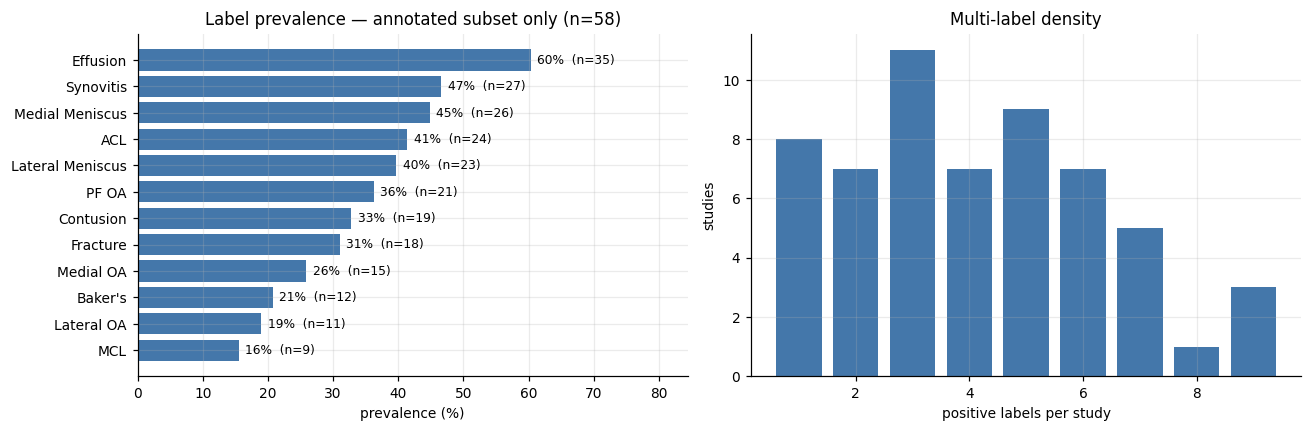


rarest: MCL with 9 positives.
Macro-AUC weights every label at 1/12 regardless of rarity (overview.md s3),
and AUC standard error scales ~1/sqrt(n_pos): the rare tail is where the
competition is won, and where CV noise is largest.


In [23]:
prev = pd.DataFrame({
    "positives": ann.sum(),
    "negatives": (ann == 0).sum(),
    "prevalence_%": (ann.mean() * 100).round(1),
}).loc[LABELS].sort_values("prevalence_%")
print(prev.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.barh(prev.index, prev["prevalence_%"], color=BLUE)
for i, (v, n) in enumerate(zip(prev["prevalence_%"], prev["positives"])):
    ax.text(v + 1, i, f"{v:.0f}%  (n={n})", va="center", fontsize=8)
ax.set_xlim(0, max(prev["prevalence_%"]) * 1.4)
ax.set_xlabel("prevalence (%)")
ax.set_title(f"Label prevalence — annotated subset only (n={len(ann)})")

ax = axes[1]
counts = ann.sum(axis=1).value_counts().sort_index()
ax.bar(counts.index, counts.values, color=BLUE)
ax.set_xlabel("positive labels per study")
ax.set_ylabel("studies")
ax.set_title("Multi-label density")
plt.tight_layout()
plt.show()

print(f"\nrarest: {prev['positives'].idxmin()} with {prev['positives'].min()} positives.")
print("Macro-AUC weights every label at 1/12 regardless of rarity (overview.md s3),")
print("and AUC standard error scales ~1/sqrt(n_pos): the rare tail is where the")
print("competition is won, and where CV noise is largest.")
findings["label_positives"] = {k: int(v) for k, v in prev["positives"].items()}

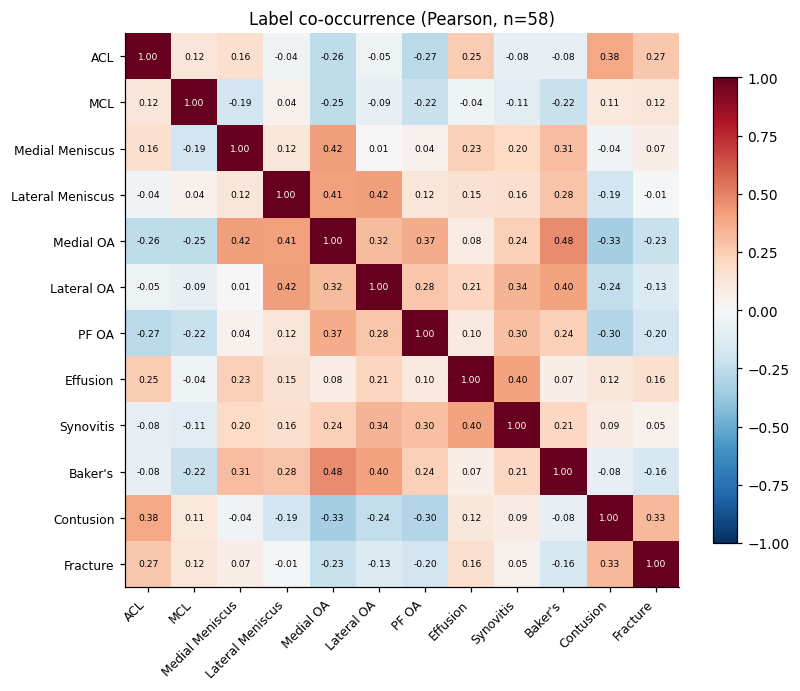

strongest positive pairs:
Medial OA         Baker's       0.48
Medial Meniscus   Medial OA     0.42
Lateral Meniscus  Lateral OA    0.42
                  Medial OA     0.41
Lateral OA        Baker's       0.40
Effusion          Synovitis     0.40

strongest negative pairs:
Medial OA  Contusion   -0.33
PF OA      Contusion   -0.30
ACL        PF OA       -0.27
           Medial OA   -0.26

A shared trunk with 12 heads should exploit this structure for free;
the OA cluster and Effusion/Synovitis are the obvious beneficiaries.


In [24]:
co = ann.corr().loc[LABELS, LABELS]

fig, ax = plt.subplots(figsize=(7.6, 6.4))
im = ax.imshow(co, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(12), LABELS, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(12), LABELS, fontsize=8)
for i in range(12):
    for j in range(12):
        v = co.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6,
                color="white" if abs(v) > 0.6 else "black")
ax.grid(False)
plt.colorbar(im, shrink=0.8)
ax.set_title(f"Label co-occurrence (Pearson, n={len(ann)})")
plt.tight_layout()
plt.show()

pairs = co.where(np.triu(np.ones(co.shape), k=1).astype(bool)).stack().sort_values()
print("strongest positive pairs:")
print(pairs.tail(6)[::-1].round(2).to_string())
print("\nstrongest negative pairs:")
print(pairs.head(4).round(2).to_string())
print("\nA shared trunk with 12 heads should exploit this structure for free;")
print("the OA cluster and Effusion/Synovitis are the obvious beneficiaries.")

## 5. Reports — the label source

Every study has a report; almost none have labels. That makes this the most
consequential section in the notebook: the reports *are* the training signal.

In [25]:
reports_at_test = "Report" in test.columns
print(f">>> Q1: reports available at test time? {reports_at_test}")
print("    -> TRAIN-ONLY privileged signal; the submitted model must be image-only"
      if not reports_at_test else
      "    -> reports ARE available at inference; text dominates")

for name, path in sorted(CSVS.items()):
    if "test" in name:
        print(f"    {name}.csv columns: {pd.read_csv(path, nrows=0).columns.tolist()}")

rep = train["Report"].fillna("")
chars, tokens = rep.str.len(), rep.str.split().str.len()
print(f"\nreports present: {(rep.str.strip() != '').sum()}/{len(rep)}")
print(pd.DataFrame({"chars": chars, "tokens": tokens})
      .describe(percentiles=[0.05, 0.5, 0.95]).round(0).to_string())

findings["reports_at_test_time"] = bool(reports_at_test)
findings["report_median_chars"] = int(chars.median())

>>> Q1: reports available at test time? False
    -> TRAIN-ONLY privileged signal; the submitted model must be image-only
    test.csv columns: ['StudyInstanceUID']
    test_series.csv columns: ['StudyInstanceUID', 'SeriesInstanceUID', 'Fluid_Sensitive', 'Fat_Suppression', 'Anatomical_Plane']

reports present: 4407/4407
        chars  tokens
count  4407.0  4407.0
mean   1098.0   148.0
std     694.0    95.0
min      52.0     8.0
5%      205.0    28.0
50%     977.0   129.0
95%    2453.0   330.0
max    4743.0   690.0


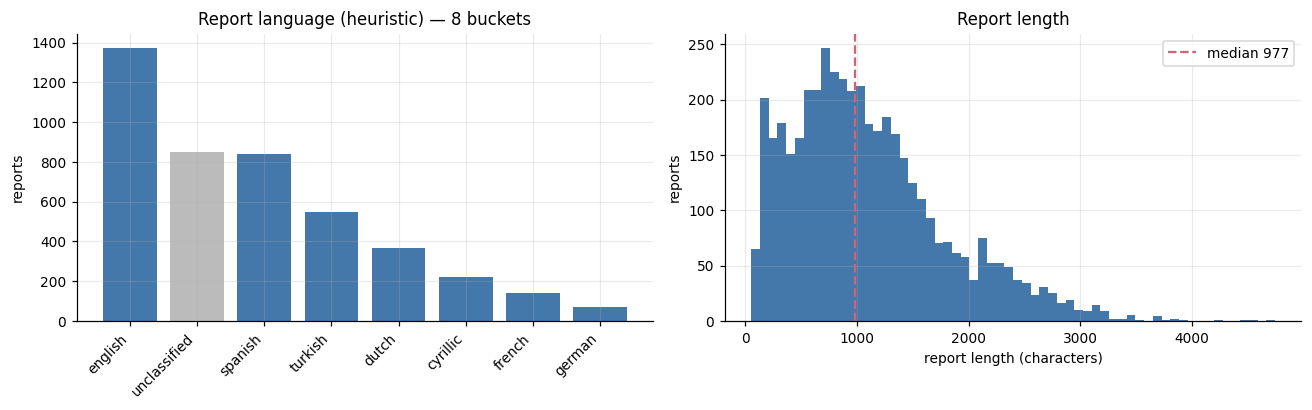

Report
english         1375
unclassified     849
spanish          841
turkish          546
dutch            366
cyrillic         220
french           140
german            70

unclassified: 19.3%
>>> multilingual corpus. Plan for a multilingual text encoder (XLM-R,
    mBERT, LaBSE) or a translation step. English-only clinical models
    such as RadBERT or BioClinicalBERT will not transfer.


In [26]:
# Language mix. A keyword heuristic on purpose: fastText/langdetect may not be
# installable offline, and the unclassified share is reported, not hidden.
KEYWORDS = {
    "english": ("findings", "impression", "technique", "exam type", "knee joint"),
    "spanish": ("técnica", "hallazgos", "rodilla", "menisco", "impresión", "derrame"),
    "dutch": ("bevindingen", "klinische", "knie", "meniscus", "onderzoek", "kruisband"),
    "german": ("befund", "kniegelenk", "beurteilung", "aufnahme", "kreuzband"),
    "french": ("constatations", "genou", "ménisque", "aucune", "articulaire", "chondropat"),
    "turkish": ("diz", "tetkik", "eklemi", "mrg", "sıvı", "kemik"),
    "italian": ("ginocchio", "reperti", "versamento"),
    "portuguese": ("joelho", "achados", "derrame articular"),
}


def has_cyrillic(t):
    return any("Ѐ" <= ch <= "ӿ" for ch in t)


def guess_language(t):
    if has_cyrillic(t):
        return "cyrillic"
    low = t.lower()
    hits = {k: sum(w in low for w in ws) for k, ws in KEYWORDS.items()}
    best = max(hits, key=hits.get)
    return best if hits[best] else "unclassified"


langs = rep.map(guess_language)
vc = langs.value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(range(len(vc)), vc.values,
            color=[GREY if i == "unclassified" else BLUE for i in vc.index])
axes[0].set_xticks(range(len(vc)), vc.index, rotation=45, ha="right")
axes[0].set_ylabel("reports")
axes[0].set_title(f"Report language (heuristic) — {len(vc)} buckets")

axes[1].hist(chars, bins=60, color=BLUE)
axes[1].axvline(chars.median(), color=RED, ls="--", label=f"median {int(chars.median())}")
axes[1].set_xlabel("report length (characters)")
axes[1].set_ylabel("reports")
axes[1].legend()
axes[1].set_title("Report length")
plt.tight_layout()
plt.show()

print(vc.to_string())
print(f"\nunclassified: {vc.get('unclassified', 0) / len(rep) * 100:.1f}%")
print(">>> multilingual corpus. Plan for a multilingual text encoder (XLM-R,")
print("    mBERT, LaBSE) or a translation step. English-only clinical models")
print("    such as RadBERT or BioClinicalBERT will not transfer.")
findings["report_languages"] = {k: int(v) for k, v in vc.items()}
findings["n_report_languages"] = int(len(vc))

In [ ]:
# Section structure -- templated reports are much easier to parse.
lead = rep.str.strip().str.split(r"[:\n]", n=1, regex=True).str[0].str.slice(0, 30)
print("most common leading field:")
print(lead.value_counts().head(12).to_string())

print("\nsection-keyword coverage:")
for s in ("findings", "impression", "conclusion", "technique",
          "hallazgos", "bevindingen", "constatations", "tetkik"):
    print(f"  {s:14} {rep.str.lower().str.contains(s).mean() * 100:5.1f}%")

print("\n" + "=" * 76)
for lang in vc.index[:5]:
    ex = rep[langs == lang].iloc[0]
    print(f"\n--- {lang} ---\n{ex[:340]}")

### Weak-label feasibility

If labels must come from reports, the first question is whether report text is
even predictive of the annotated labels. Below is a deliberately crude
multilingual keyword matcher, scored against the annotated subset. It is a
**feasibility probe, not the extractor** — but if precision here is poor, the
whole weak-supervision plan needs rethinking before any GPU time is spent.

keyword hit rate across all 4407 reports:
ACL                 40.6
MCL                 34.2
Medial Meniscus     43.5
Lateral Meniscus    38.3
Medial OA            0.7
Lateral OA           0.0
PF OA               32.5
Effusion            65.9
Synovitis           10.0
Baker's             35.7
Contusion           17.0
Fracture            18.4

keyword matcher vs the 58 annotated studies:
                  tp  fp  fn  tn  precision  recall  accuracy
label                                                        
ACL               17  17   7  17       0.50    0.71      0.59
MCL                7  20   2  29       0.26    0.78      0.62
Medial Meniscus   13  18  13  14       0.42    0.50      0.47
Lateral Meniscus  16  12   7  23       0.57    0.70      0.67
Medial OA          0   0  15  43        NaN    0.00      0.74
Lateral OA         0   0  11  47        NaN    0.00      0.81
PF OA              4  12  17  25       0.25    0.19      0.50
Effusion          28  18   7   5       0.61    0.80   

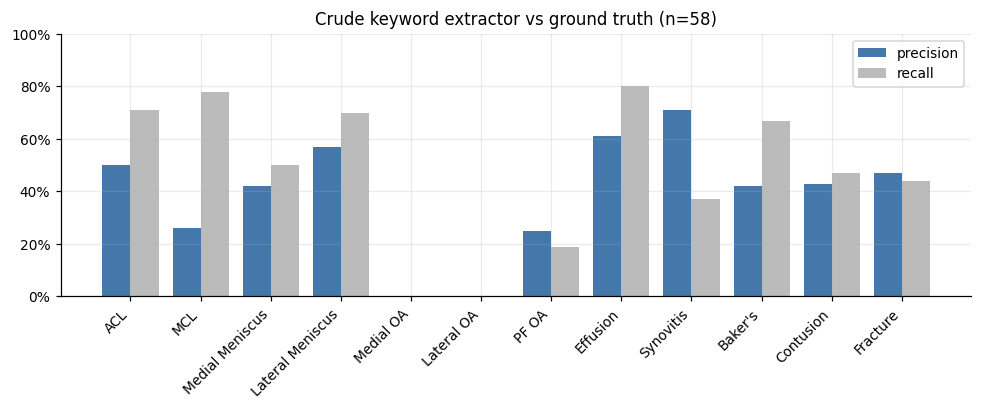


mean precision 0.46  mean recall 0.47
Interpretation: an unengineered baseline on a tiny anchor set. Treat it as
a floor to beat. The real extractor should be a multilingual model or a
per-language rule set, validated on exactly these annotated studies.


In [28]:
# Multilingual surface forms per target. Intentionally small and auditable.
LABEL_TERMS = {
    "ACL": ["anterior cruciate", "acl ", "lca", "voorste kruisband",
            "ligament croisé antérieur", "ön çapraz", "предна кръстна"],
    "MCL": ["medial collateral", "mcl ", "colateral medial",
            "mediale collaterale", "collatéral médial", "iç yan bağ"],
    "Medial Meniscus": ["medial meniscus", "menisco interno", "menisco medial",
                        "mediale meniscus", "ménisque interne", "iç menisküs",
                        "медиалния мениск"],
    "Lateral Meniscus": ["lateral meniscus", "menisco externo", "menisco lateral",
                         "laterale meniscus", "ménisque externe", "dış menisküs"],
    "Medial OA": ["medial compartment osteoarthr", "artrosis femorotibial medial",
                  "mediale gonartrose", "fémoro-tibiale interne"],
    "Lateral OA": ["lateral compartment osteoarthr", "artrosis femorotibial externa",
                   "laterale gonartrose", "fémoro-tibiale externe"],
    "PF OA": ["patellofemoral", "femoropatelar", "rétropatellaire",
              "retropatellar", "patellofemoraal"],
    "Effusion": ["effusion", "derrame", "vocht", "épanchement", "sıvı",
                 "излив", "hydrops"],
    "Synovitis": ["synovitis", "sinovitis", "synovite", "sinovit"],
    "Baker's": ["baker", "popliteal cyst", "quiste poplíteo", "kyste poplité",
                "popliteal kist"],
    "Contusion": ["contusion", "bone marrow oedema", "bone marrow edema",
                  "edema óseo", "beenmergoedeem", "œdème osseux", "kemik ödem",
                  "костномозъчен едем"],
    "Fracture": ["fracture", "fractura", "fractuur", "kırık", "fraktur"],
}

low = rep.str.lower()
hit = pd.DataFrame(
    {lab: low.apply(lambda t, ts=terms: any(x in t for x in ts))
     for lab, terms in LABEL_TERMS.items()}
)[LABELS]

print(f"keyword hit rate across all {len(train)} reports:")
print((hit.mean() * 100).round(1).to_string())

y, p = ann, hit[is_labelled]
rows = []
for lab in LABELS:
    tp = int(((p[lab]) & (y[lab] == 1)).sum())
    fp = int(((p[lab]) & (y[lab] == 0)).sum())
    fn = int(((~p[lab]) & (y[lab] == 1)).sum())
    tn = int(((~p[lab]) & (y[lab] == 0)).sum())
    rows.append({"label": lab, "tp": tp, "fp": fp, "fn": fn, "tn": tn,
                 "precision": tp / (tp + fp) if tp + fp else np.nan,
                 "recall": tp / (tp + fn) if tp + fn else np.nan,
                 "accuracy": (tp + tn) / len(p)})
score = pd.DataFrame(rows).set_index("label").round(2)
print(f"\nkeyword matcher vs the {len(p)} annotated studies:")
print(score.to_string())

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(12)
ax.bar(x - 0.2, score["precision"], 0.4, label="precision", color=BLUE)
ax.bar(x + 0.2, score["recall"], 0.4, label="recall", color=GREY)
ax.set_xticks(x, LABELS, rotation=45, ha="right")
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend()
ax.set_title(f"Crude keyword extractor vs ground truth (n={len(p)})")
plt.tight_layout()
plt.show()

print(f"\nmean precision {score['precision'].mean():.2f}  "
      f"mean recall {score['recall'].mean():.2f}")
print("Interpretation: an unengineered baseline on a tiny anchor set. Treat it as")
print("a floor to beat. The real extractor should be a multilingual model or a")
print("per-language rule set, validated on exactly these annotated studies.")
findings["keyword_extractor_mean_precision"] = round(float(score["precision"].mean()), 3)
findings["keyword_extractor_mean_recall"] = round(float(score["recall"].mean()), 3)

## 6. Series and sequence taxonomy — Q3

>>> Fluid_Sensitive == Fat_Suppression on all 24371 rows: True
    Duplicate columns. Use ONE contrast bit; feeding both double-counts it.

joint distribution:
Fluid_Sensitive  Fat_Suppression
0                0                  10361
1                1                  14010

series per study: min 3 median 5 max 14 mean 5.5


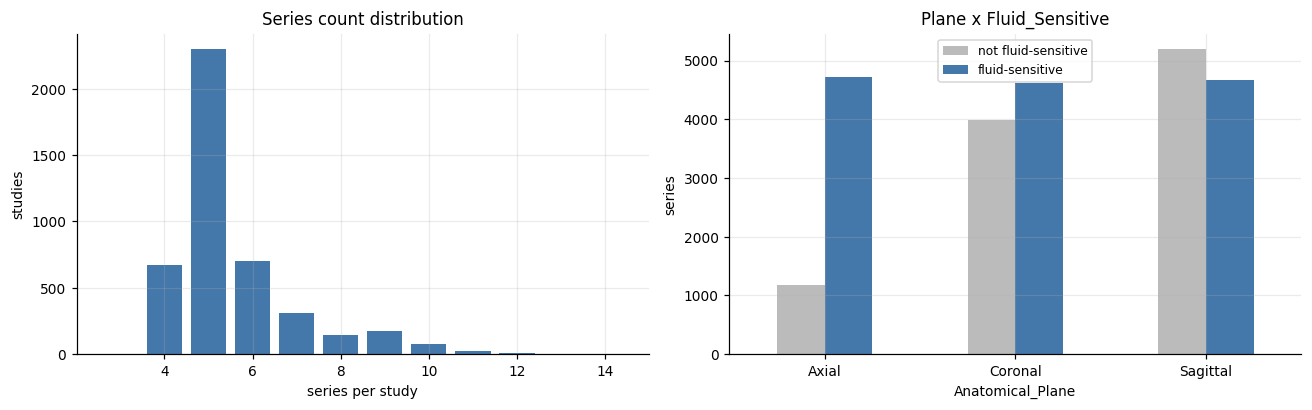

In [29]:
FLAGS = ["Fluid_Sensitive", "Fat_Suppression"]
identical = bool((series[FLAGS[0]] == series[FLAGS[1]]).all())
print(f">>> {FLAGS[0]} == {FLAGS[1]} on all {len(series)} rows: {identical}")
if identical:
    print("    Duplicate columns. Use ONE contrast bit; feeding both double-counts it.")
print(f"\njoint distribution:\n{series.groupby(FLAGS).size().to_string()}")
CONTRAST = FLAGS[0]

per_study = series.groupby("StudyInstanceUID").size()
print(f"\nseries per study: min {per_study.min()} median {int(per_study.median())} "
      f"max {per_study.max()} mean {per_study.mean():.1f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
vcs = per_study.value_counts().sort_index()
axes[0].bar(vcs.index, vcs.values, color=BLUE)
axes[0].set_xlabel("series per study")
axes[0].set_ylabel("studies")
axes[0].set_title("Series count distribution")

comp = series.groupby(["Anatomical_Plane", CONTRAST]).size().unstack(fill_value=0)
comp.plot(kind="bar", ax=axes[1], color=[GREY, BLUE], rot=0)
axes[1].set_ylabel("series")
axes[1].set_title(f"Plane x {CONTRAST}")
axes[1].legend(["not fluid-sensitive", "fluid-sensitive"], fontsize=8)
plt.tight_layout()
plt.show()

findings["fluid_fat_columns_identical"] = identical
findings["series_per_study"] = {"min": int(per_study.min()),
                                "median": int(per_study.median()),
                                "max": int(per_study.max())}

slot coverage (% of studies with >=1 such series):
slot
Axial_fs1       100.0
Sagittal_fs0     96.8
Coronal_fs1      96.4
Sagittal_fs1     94.2
Coronal_fs0      77.3
Axial_fs0        19.4

studies with every slot : 566
distinct patterns       : 12

top patterns over ['Axial_fs0', 'Axial_fs1', 'Coronal_fs0', 'Coronal_fs1', 'Sagittal_fs0', 'Sagittal_fs1']:
011111    2516
010111     745
111111     566
110110     229
011011     157
011101     120
110111      23
111101      21


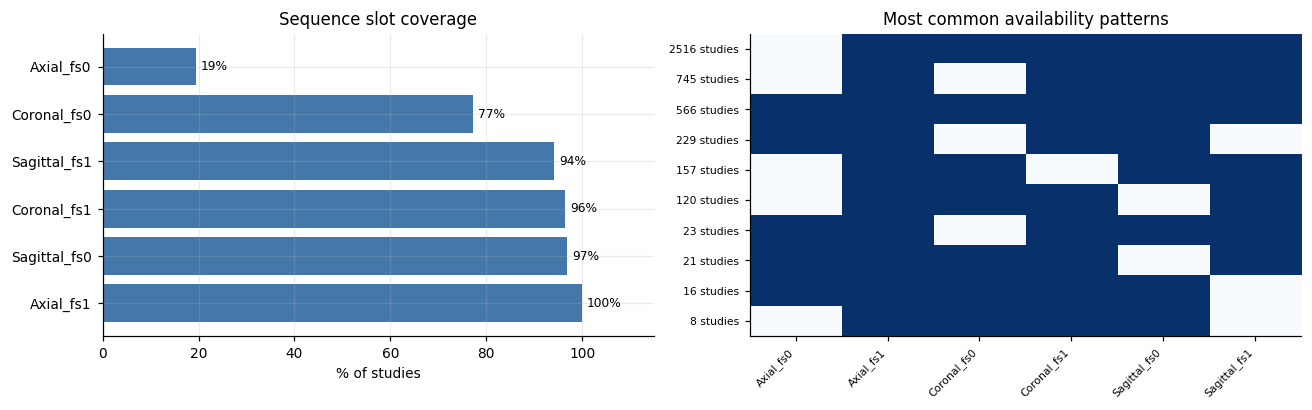


>>> 'Axial_fs1' is present in 100% of studies -- the natural
    single-series starting point for a first model.


In [30]:
# Slot availability. Missingness is an input state, not grounds for dropping a
# study (arch s7.5) -- the fusion layer must tolerate absent slots.
series["slot"] = series["Anatomical_Plane"] + "_fs" + series[CONTRAST].astype(str)
avail = (series.assign(one=1)
         .pivot_table(index="StudyInstanceUID", columns="slot", values="one",
                      aggfunc="sum", fill_value=0) > 0)

cov = (avail.mean() * 100).sort_values(ascending=False)
print("slot coverage (% of studies with >=1 such series):")
print(cov.round(1).to_string())

patterns = avail.astype(int).astype(str).agg("".join, axis=1).value_counts()
print(f"\nstudies with every slot : {int(avail.all(axis=1).sum())}")
print(f"distinct patterns       : {len(patterns)}")
print(f"\ntop patterns over {list(avail.columns)}:")
print(patterns.head(8).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].barh(cov.index, cov.values, color=BLUE)
for i, v in enumerate(cov.values):
    axes[0].text(v + 1, i, f"{v:.0f}%", va="center", fontsize=8)
axes[0].set_xlim(0, 115)
axes[0].set_xlabel("% of studies")
axes[0].set_title("Sequence slot coverage")

top = patterns.head(10)
axes[1].imshow([[int(ch) for ch in idx] for idx in top.index],
               cmap="Blues", aspect="auto", vmin=0, vmax=1)
axes[1].set_xticks(range(len(avail.columns)), avail.columns,
                   rotation=45, ha="right", fontsize=7)
axes[1].set_yticks(range(len(top)), [f"{v} studies" for v in top.values], fontsize=7)
axes[1].grid(False)
axes[1].set_title("Most common availability patterns")
plt.tight_layout()
plt.show()

best_slot = str(cov.idxmax())
print(f"\n>>> '{best_slot}' is present in {cov.max():.0f}% of studies -- the natural")
print("    single-series starting point for a first model.")
findings["slot_coverage_pct"] = cov.round(1).to_dict()
findings["most_available_slot"] = best_slot

## 7. DICOM geometry — the input-representation decision

Everything below needs pixel files, so it runs on Kaggle only. This section
decides 2D vs 2.5D vs 3D, so it surveys many series rather than one.

In [31]:
try:
    import pydicom
    HAVE_PYDICOM = True
except ImportError:
    HAVE_PYDICOM = False

HAVE_IMAGES = bool(TRAIN_IMAGES) and HAVE_PYDICOM
print(f"pydicom available : {HAVE_PYDICOM}")
print(f"train images at   : {TRAIN_IMAGES}")
print(f"pixel sections    : {'ENABLED' if HAVE_IMAGES else 'SKIPPED'}")

GEOM_STUDIES = 80   # header-only reads; raise for a tighter estimate
PROBE_N = 400       # studies sampled for acquisition metadata

pydicom available : True
train images at   : /kaggle/input/competitions/rsna-knee-abnormality-detection/train_series
pixel sections    : ENABLED


In [32]:
if HAVE_IMAGES:
    study_dirs = sorted(p for p in TRAIN_IMAGES.iterdir() if p.is_dir())
    print(f"study directories: {len(study_dirs)}  (train.csv rows: {len(train)})")

    rows = []
    for st in study_dirs[:GEOM_STUDIES]:
        for sd in (q for q in st.iterdir() if q.is_dir()):
            files = list(sd.glob("*.dcm"))
            if not files:
                continue
            d = pydicom.dcmread(files[0], stop_before_pixels=True)
            ps = getattr(d, "PixelSpacing", None)
            rows.append({
                "study": st.name, "series": sd.name, "slices": len(files),
                "rows": int(getattr(d, "Rows", 0)),
                "cols": int(getattr(d, "Columns", 0)),
                "in_plane_mm": float(ps[0]) if ps else np.nan,
                "thickness_mm": float(getattr(d, "SliceThickness", 0) or np.nan),
                "spacing_mm": float(getattr(d, "SpacingBetweenSlices", 0) or np.nan),
                "desc": str(getattr(d, "SeriesDescription", ""))[:30],
            })
    geom = pd.DataFrame(rows).merge(
        series[["SeriesInstanceUID", "Anatomical_Plane", CONTRAST]],
        left_on="series", right_on="SeriesInstanceUID", how="left")

    step = geom["spacing_mm"].fillna(geom["thickness_mm"])
    geom["anisotropy"] = step / geom["in_plane_mm"]
    geom["gap_mm"] = step - geom["thickness_mm"]

    geom["aspect"] = geom["cols"] / geom["rows"]
    geom["fov_mm"] = geom["rows"] * geom["in_plane_mm"]
    geom["span_mm"] = geom["slices"] * step

    print(f"\nsurveyed {len(geom)} series across {GEOM_STUDIES} studies\n")
    print(geom[["slices", "rows", "cols", "aspect", "in_plane_mm", "thickness_mm",
                "spacing_mm", "fov_mm", "span_mm"]]
          .describe(percentiles=[0.05, 0.5, 0.95]).round(2).to_string())

    # Total dataset size at slice level, extrapolated from the survey.
    mean_slices = float(geom["slices"].mean())
    est_images = mean_slices * len(series)
    print(f"\n--- dataset size at three levels ---")
    print(f"  studies (submission rows) : {train['StudyInstanceUID'].nunique():,}")
    print(f"  series                    : {len(series):,}")
    print(f"  slices / .dcm images      : ~{est_images:,.0f} "
          f"(estimated: {mean_slices:.1f} mean slices x {len(series):,} series)")
    print(f"\naspect ratio: min {geom['aspect'].min():.3f} max {geom['aspect'].max():.3f} "
          f"-- {'all square' if geom['aspect'].nunique() == 1 else 'NON-SQUARE present'}")
    print(f"field of view: median {geom['fov_mm'].median():.0f} mm in-plane, "
          f"{geom['span_mm'].median():.0f} mm through-plane")
    findings["estimated_total_slices"] = int(est_images)
    findings["mean_slices_per_series"] = round(mean_slices, 1)
    findings["aspect_ratios"] = sorted(geom["aspect"].round(3).unique().tolist())

study directories: 4407  (train.csv rows: 4407)

surveyed 454 series across 80 studies

       slices     rows     cols  aspect  in_plane_mm  thickness_mm  spacing_mm  fov_mm  span_mm
count  454.00   454.00   454.00  454.00       454.00        454.00      425.00  454.00   454.00
mean    35.06   544.17   542.07    1.00         0.33          3.14        3.68  163.11   108.61
std     34.21   182.47   182.07    0.02         0.11          0.70        0.92   14.35    22.61
min     11.00   192.00   192.00    0.81         0.14          0.60        0.40   99.99    24.75
5%      18.00   320.00   320.00    1.00         0.16          2.00        2.20  140.00    79.93
50%     30.00   512.00   512.00    1.00         0.31          3.00        3.50  160.00   105.60
95%     45.35  1024.00  1024.00    1.00         0.56          4.00        5.02  190.00   146.82
max    320.00  1024.00  1024.00    1.03         0.89          5.40        7.72  220.02   180.00

--- dataset size at three levels ---
  studies 

matrix sizes:
rows  cols
512   512     119
640   640      67
384   384      45
320   320      36
1024  1024     33
528   528      21
256   256      19
480   480      18

per-plane medians:
                  slices  in_plane_mm  thickness_mm  anisotropy
Anatomical_Plane                                               
Axial               31.0         0.31           3.0       12.80
Coronal             30.0         0.31           3.0       11.84
Sagittal            29.0         0.31           3.0       11.20


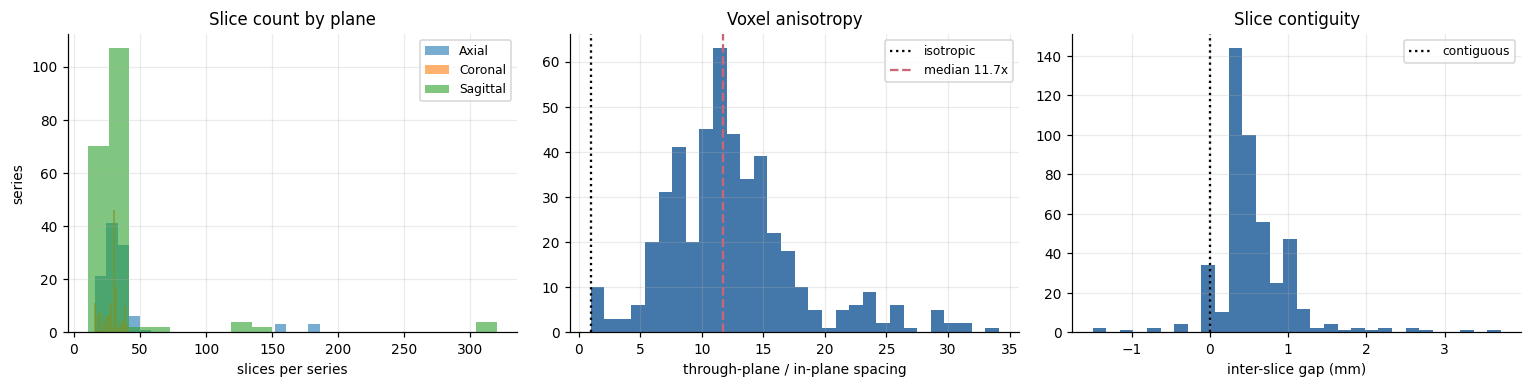


>>> median anisotropy 11.7x | median 30 slices | 91% of series have gaps > 0.1 mm
    Volumes are thin and highly anisotropic, and slices are not
    contiguous. Isotropic 3D resampling would be mostly interpolated.
    DECISION: 2D / 2.5D stacks are the baseline; 3D is an ablation,
    not the default (revises arch s7.2).
    In-plane matrix size varies, so resize/crop is mandatory.


In [33]:
if HAVE_IMAGES:
    print("matrix sizes:")
    print(geom.groupby(["rows", "cols"]).size().sort_values(ascending=False).head(8).to_string())
    print("\nper-plane medians:")
    print(geom.groupby("Anatomical_Plane")[
        ["slices", "in_plane_mm", "thickness_mm", "anisotropy"]].median().round(2).to_string())

    fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
    for plane, grp in geom.groupby("Anatomical_Plane"):
        axes[0].hist(grp["slices"], bins=20, alpha=0.6, label=plane)
    axes[0].set_xlabel("slices per series")
    axes[0].set_ylabel("series")
    axes[0].legend(fontsize=8)
    axes[0].set_title("Slice count by plane")

    axes[1].hist(geom["anisotropy"].dropna(), bins=30, color=BLUE)
    axes[1].axvline(1, color="k", ls=":", label="isotropic")
    axes[1].axvline(geom["anisotropy"].median(), color=RED, ls="--",
                    label=f"median {geom['anisotropy'].median():.1f}x")
    axes[1].set_xlabel("through-plane / in-plane spacing")
    axes[1].legend(fontsize=8)
    axes[1].set_title("Voxel anisotropy")

    axes[2].hist(geom["gap_mm"].dropna(), bins=30, color=BLUE)
    axes[2].axvline(0, color="k", ls=":", label="contiguous")
    axes[2].set_xlabel("inter-slice gap (mm)")
    axes[2].legend(fontsize=8)
    axes[2].set_title("Slice contiguity")
    plt.tight_layout()
    plt.show()

    med_a = float(geom["anisotropy"].median())
    med_s = float(geom["slices"].median())
    gap_pct = float((geom["gap_mm"] > 0.1).mean() * 100)
    print(f"\n>>> median anisotropy {med_a:.1f}x | median {med_s:.0f} slices | "
          f"{gap_pct:.0f}% of series have gaps > 0.1 mm")
    if med_a > 4 or med_s < 40:
        print("    Volumes are thin and highly anisotropic, and slices are not")
        print("    contiguous. Isotropic 3D resampling would be mostly interpolated.")
        print("    DECISION: 2D / 2.5D stacks are the baseline; 3D is an ablation,")
        print("    not the default (revises arch s7.2).")
    else:
        print("    Volumes support genuine 3D modelling.")
    print("    In-plane matrix size varies, so resize/crop is mandatory.")

    findings["median_anisotropy"] = round(med_a, 1)
    findings["median_slices_per_series"] = med_s
    findings["pct_series_with_gaps"] = round(gap_pct, 1)

In [34]:
if HAVE_IMAGES:
    # Slice ordering. Sorting by filename or InstanceNumber can silently scramble
    # a volume; the physical check is projection onto the slice normal.
    bad = checked = 0
    for _, r in geom.head(25).iterrows():
        sd = TRAIN_IMAGES / r["study"] / r["series"]
        metas = []
        for f in sd.glob("*.dcm"):
            d = pydicom.dcmread(f, stop_before_pixels=True)
            ipp = getattr(d, "ImagePositionPatient", None)
            iop = getattr(d, "ImageOrientationPatient", None)
            if ipp is None or iop is None:
                continue
            metas.append((f.name, np.array(ipp, float), np.array(iop, float),
                          int(getattr(d, "InstanceNumber", 0))))
        if len(metas) < 3:
            continue
        normal = np.cross(metas[0][2][:3], metas[0][2][3:])
        geo_order = [m[0] for m in sorted(metas, key=lambda m: float(np.dot(m[1], normal)))]
        inst_order = [m[0] for m in sorted(metas, key=lambda m: m[3])]
        checked += 1
        bad += geo_order != inst_order

    print(f"series checked: {checked}")
    print(f"InstanceNumber order disagrees with geometry: {bad}")
    print(">>> InstanceNumber is a safe sort key on this sample"
          if bad == 0 else
          ">>> InstanceNumber is NOT reliable -- always sort by ImagePositionPatient")
    findings["instance_number_order_mismatches"] = int(bad)
    findings["instance_number_series_checked"] = int(checked)

series checked: 25
InstanceNumber order disagrees with geometry: 10
>>> InstanceNumber is NOT reliable -- always sort by ImagePositionPatient


## 8. Acquisition metadata — patient linkage (Q2), laterality, scanners

In [35]:
VENDOR_ALIASES = {"siemens": "Siemens", "philips": "Philips", "ge medical": "GE",
                  "ge health": "GE", "toshiba": "Toshiba", "canon": "Canon",
                  "hitachi": "Hitachi"}


def normalise_vendor(raw):
    low = str(raw).strip().lower()
    for k, v in VENDOR_ALIASES.items():
        if low.startswith(k):
            return v
    return low.title() or "(blank)"


if HAVE_IMAGES:
    probe = []
    for st in study_dirs[:PROBE_N]:
        f = next(st.rglob("*.dcm"), None)
        if f is None:
            continue
        d = pydicom.dcmread(f, stop_before_pixels=True)
        probe.append({
            "study": st.name,
            "PatientID": str(getattr(d, "PatientID", "")).strip(),
            "Laterality": str(getattr(d, "ImageLaterality", "")
                              or getattr(d, "Laterality", "")).strip(),
            "BodyPart": str(getattr(d, "BodyPartExamined", "")).strip(),
            "Vendor": normalise_vendor(getattr(d, "Manufacturer", "")),
            "Tesla": str(getattr(d, "MagneticFieldStrength", "")).strip(),
            "Age": str(getattr(d, "PatientAge", "")).strip(),
            "Sex": str(getattr(d, "PatientSex", "")).strip(),
        })
    probe = pd.DataFrame(probe)
    print(f"probed {len(probe)} of {len(study_dirs)} studies\n")

    ids = probe.loc[probe["PatientID"] != "", "PatientID"]
    dup = ids.value_counts()
    dup = dup[dup > 1]
    print(f"PatientID populated   : {len(ids)}/{len(probe)}")
    print(f"unique PatientIDs     : {ids.nunique()}")
    print(f"patients with >1 study: {len(dup)}")
    print(f">>> Q2: patient grouping required? {len(dup) > 0}")
    print("    -> use GroupKFold on PatientID" if len(dup) else
          f"    -> study-level folds appear safe across these {len(probe)} studies")

    lat_missing = float((probe["Laterality"] == "").mean() * 100)
    print(f"\nLaterality missing on {lat_missing:.1f}% of probed studies")
    print(">>> left/right canonicalisation cannot rely on this tag; it needs an")
    print("    image-derived fallback, or the policy must be abandoned (arch s5.3)")

    findings["probe_n"] = int(len(probe))
    findings["patients_with_multiple_studies"] = int(len(dup))
    findings["laterality_missing_pct"] = round(lat_missing, 1)

probed 400 of 4407 studies

PatientID populated   : 400/400
unique PatientIDs     : 400
patients with >1 study: 0
>>> Q2: patient grouping required? False
    -> study-level folds appear safe across these 400 studies

Laterality missing on 50.7% of probed studies
>>> left/right canonicalisation cannot rely on this tag; it needs an
    image-derived fallback, or the policy must be abandoned (arch s5.3)


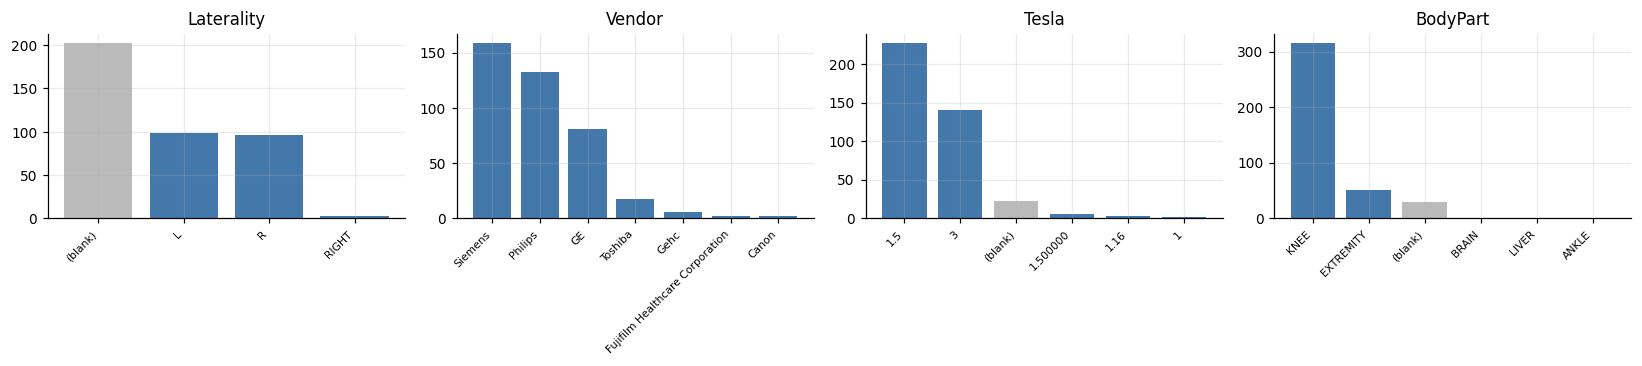


Vendor:
Vendor
Siemens                            159
Philips                            132
GE                                  81
Toshiba                             17
Gehc                                 6
Fujifilm Healthcare Corporation      2

Tesla:
Tesla
1.5         228
3           140
(blank)      22
1.500000      6
1.16          3
1             1

Sex:
Sex
M          196
F          168
(blank)     22
O           14

>>> Multiple vendors and field strengths mean real domain shift.
    Consider vendor-stratified validation, and intensity normalisation
    fitted per training fold only.


In [36]:
if HAVE_IMAGES:
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
    for ax, col in zip(axes, ["Laterality", "Vendor", "Tesla", "BodyPart"]):
        v = probe[col].replace("", "(blank)").value_counts().head(7)
        ax.bar(range(len(v)), v.values,
               color=[GREY if i == "(blank)" else BLUE for i in v.index])
        ax.set_xticks(range(len(v)), v.index, rotation=45, ha="right", fontsize=7)
        ax.set_title(col)
    plt.tight_layout()
    plt.show()

    for col in ["Vendor", "Tesla", "Sex"]:
        print(f"\n{col}:")
        print(probe[col].replace("", "(blank)").value_counts().head(6).to_string())

    print("\n>>> Multiple vendors and field strengths mean real domain shift.")
    print("    Consider vendor-stratified validation, and intensity normalisation")
    print("    fitted per training fold only.")
    findings["vendors"] = probe["Vendor"].value_counts().to_dict()

### DICOM tag availability

In [37]:
if HAVE_IMAGES:
    # Which tags can preprocessing actually rely on? A tag present in only some
    # studies needs a documented fallback (arch section 5.4).
    TAGS = ["PatientID", "PatientAge", "PatientSex", "ImageLaterality", "Laterality",
            "BodyPartExamined", "Manufacturer", "ManufacturerModelName",
            "MagneticFieldStrength", "SeriesDescription", "ProtocolName",
            "PixelSpacing", "SliceThickness", "SpacingBetweenSlices",
            "ImagePositionPatient", "ImageOrientationPatient", "InstanceNumber",
            "RescaleSlope", "RescaleIntercept", "EchoTime", "RepetitionTime",
            "InversionTime", "ScanningSequence", "MRAcquisitionType"]

    present = {t: 0 for t in TAGS}
    n = 0
    for st in study_dirs[:150]:
        f = next(st.rglob("*.dcm"), None)
        if f is None:
            continue
        d = pydicom.dcmread(f, stop_before_pixels=True)
        n += 1
        for t in TAGS:
            v = getattr(d, t, None)
            if v is not None and str(v).strip() != "":
                present[t] += 1

    tags = (pd.Series(present) / n * 100).sort_values(ascending=False).round(1)
    print(f"tag availability across {n} studies (% present and non-empty):\n")
    print(tags.to_string())

    unreliable = tags[(tags > 0) & (tags < 99)]
    print(f"\ntags present but not universal ({len(unreliable)}):")
    print(unreliable.to_string() if len(unreliable) else "  none")
    print(f"\ntags always absent: {tags[tags == 0].index.tolist()}")
    print("\n>>> Anything below 100% needs an explicit fallback in preprocessing.")
    findings["dicom_tag_availability_pct"] = tags.to_dict()

tag availability across 150 studies (% present and non-empty):

PatientID                  100.0
ManufacturerModelName      100.0
Manufacturer               100.0
InstanceNumber             100.0
SliceThickness             100.0
ImagePositionPatient       100.0
ImageOrientationPatient    100.0
PixelSpacing               100.0
SeriesDescription           97.3
MRAcquisitionType           94.0
ScanningSequence            94.0
MagneticFieldStrength       94.0
PatientSex                  94.0
RepetitionTime              94.0
EchoTime                    94.0
BodyPartExamined            92.7
SpacingBetweenSlices        92.7
Laterality                  47.3
RescaleIntercept            42.7
RescaleSlope                42.7
InversionTime                4.7
ImageLaterality              0.0
PatientAge                   0.0
ProtocolName                 0.0

tags present but not universal (13):
SeriesDescription        97.3
MRAcquisitionType        94.0
ScanningSequence         94.0
MagneticFieldStr

## 9. Pixel data — reusable loader

`load_volume` below is the reference implementation for the project: it orders
slices physically, windows intensities by percentile, resizes to a fixed matrix
and samples a fixed slice count. The **same** transform must be used at training
and inference (arch §5.3), so this belongs in `src/kappa/data/` once settled.

In [38]:
if HAVE_IMAGES:
    from PIL import Image

    def load_volume(study_uid, series_uid, n_slices=16, size=224,
                    split="train_series", window=(1, 99)):
        """Return uint8 (n_slices, size, size), slices in physical order.

        Sorts by projection onto the slice normal, falling back to
        InstanceNumber when orientation tags are absent. Percentile windowing is
        per-series because MR intensity has no absolute scale.
        """
        sdir = DATA / split / study_uid / series_uid
        files = sorted(sdir.glob("*.dcm"))
        if not files:
            raise FileNotFoundError(sdir)

        ds = [pydicom.dcmread(f) for f in files]
        iop = getattr(ds[0], "ImageOrientationPatient", None)
        if iop is not None and all(hasattr(d, "ImagePositionPatient") for d in ds):
            normal = np.cross(np.array(iop[:3], float), np.array(iop[3:], float))
            ds.sort(key=lambda d: float(np.dot(np.array(d.ImagePositionPatient, float), normal)))
        else:
            ds.sort(key=lambda d: int(getattr(d, "InstanceNumber", 0)))

        take = np.linspace(0, len(ds) - 1, min(n_slices, len(ds))).round().astype(int)
        out = np.zeros((n_slices, size, size), dtype=np.uint8)
        for i, t in enumerate(take):
            d = ds[t]
            img = (d.pixel_array.astype(np.float32)
                   * float(getattr(d, "RescaleSlope", 1) or 1)
                   + float(getattr(d, "RescaleIntercept", 0) or 0))
            lo, hi = np.percentile(img, window)
            img = np.clip((img - lo) / max(hi - lo, 1e-6), 0, 1)
            out[i] = np.asarray(Image.fromarray((img * 255).astype(np.uint8))
                                .resize((size, size), Image.BILINEAR))
        return out

    pick = series[series["slot"] == findings["most_available_slot"]].iloc[0]
    vol = load_volume(pick["StudyInstanceUID"], pick["SeriesInstanceUID"])
    print(f"loaded {vol.shape} from slot {findings['most_available_slot']}")
    print(f"dtype {vol.dtype}  range {vol.min()}-{vol.max()}")

loaded (16, 224, 224) from slot Axial_fs1
dtype uint8  range 0-255


In [ ]:
if HAVE_IMAGES:
    fig, axes = plt.subplots(2, 8, figsize=(16, 4.3))
    for i, ax in enumerate(axes.flat):
        ax.imshow(vol[i], cmap="gray")
        ax.set_title(str(i), fontsize=7)
        ax.axis("off")
    row = train[train["StudyInstanceUID"] == pick["StudyInstanceUID"]]
    if len(row) and bool(row[LABELS].notna().all(axis=1).iloc[0]):
        pos = [c for c in LABELS if row[c].iloc[0] == 1] or ["all negative"]
    else:
        pos = ["unlabelled"]
    plt.suptitle(f"{findings['most_available_slot']} — 16 sampled slices | "
                 f"labels: {', '.join(pos)}", fontsize=10)
    plt.tight_layout()
    plt.show()

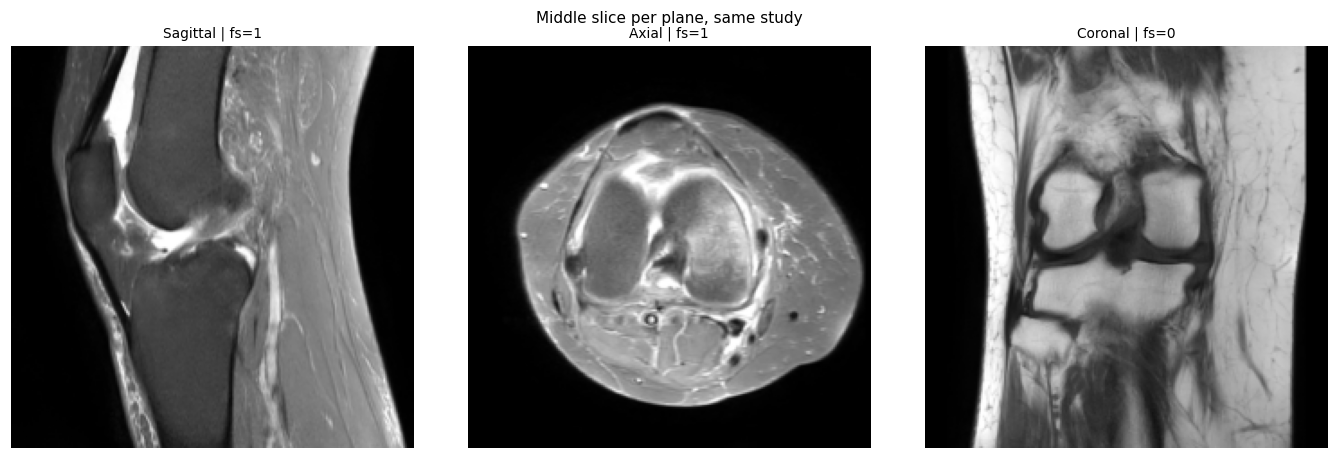

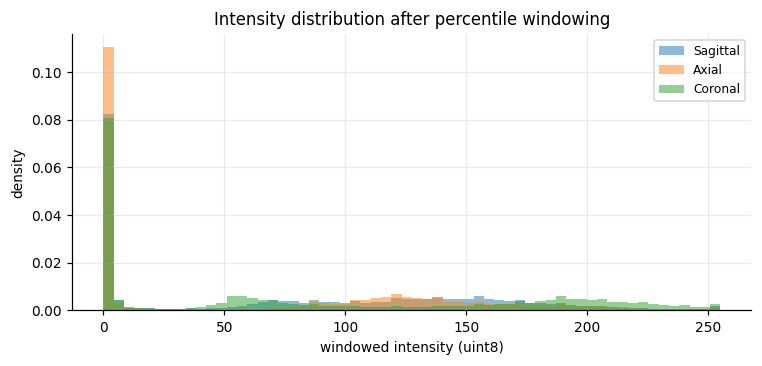

Distributions still differ by plane and sequence after windowing.
Normalisation statistics must be fitted on training folds only.


In [40]:
if HAVE_IMAGES:
    study_uid = pick["StudyInstanceUID"]
    planes = series[series["StudyInstanceUID"] == study_uid].drop_duplicates("Anatomical_Plane")

    fig, axes = plt.subplots(1, len(planes), figsize=(4.2 * len(planes), 4.2))
    raws = {}
    for ax, (_, r) in zip(np.atleast_1d(axes), planes.iterrows()):
        v = load_volume(study_uid, r["SeriesInstanceUID"], n_slices=8)
        raws[r["Anatomical_Plane"]] = v
        ax.imshow(v[len(v) // 2], cmap="gray")
        ax.set_title(f"{r['Anatomical_Plane']} | fs={r[CONTRAST]}", fontsize=9)
        ax.axis("off")
    plt.suptitle("Middle slice per plane, same study", fontsize=10)
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 3.4))
    for name, v in raws.items():
        ax.hist(v.ravel(), bins=60, alpha=0.5, label=name, density=True)
    ax.set_xlabel("windowed intensity (uint8)")
    ax.set_ylabel("density")
    ax.legend(fontsize=8)
    ax.set_title("Intensity distribution after percentile windowing")
    plt.tight_layout()
    plt.show()

    print("Distributions still differ by plane and sequence after windowing.")
    print("Normalisation statistics must be fitted on training folds only.")

### Positive vs negative gallery

Same slot, same slice position, contrasting annotated studies. This is the only
place in the notebook where pathology is actually looked at rather than counted.

In [ ]:
if HAVE_IMAGES:
    TARGET = "Effusion"   # highest-prevalence label, so both classes are available
    annotated = train[is_labelled]
    slot_series = series[series["slot"] == findings["most_available_slot"]]
    avail_ann = slot_series[slot_series["StudyInstanceUID"].isin(annotated["StudyInstanceUID"])]

    def pick_studies(value, k=4):
        uids = annotated.loc[annotated[TARGET] == value, "StudyInstanceUID"]
        rows = avail_ann[avail_ann["StudyInstanceUID"].isin(uids)]
        return rows.drop_duplicates("StudyInstanceUID").head(k)

    pos_rows, neg_rows = pick_studies(1), pick_studies(0)
    print(f"{TARGET}: {len(pos_rows)} positive and {len(neg_rows)} negative "
          f"annotated studies with a {findings['most_available_slot']} series")

    if len(pos_rows) and len(neg_rows):
        k = min(len(pos_rows), len(neg_rows), 4)
        fig, axes = plt.subplots(2, k, figsize=(3.4 * k, 7))
        axes = np.atleast_2d(axes)
        for col, (_, r) in enumerate(pos_rows.head(k).iterrows()):
            v = load_volume(r["StudyInstanceUID"], r["SeriesInstanceUID"], n_slices=9)
            axes[0, col].imshow(v[len(v) // 2], cmap="gray")
            axes[0, col].set_title(f"{TARGET} = 1", fontsize=9, color="#AA3333")
            axes[0, col].axis("off")
        for col, (_, r) in enumerate(neg_rows.head(k).iterrows()):
            v = load_volume(r["StudyInstanceUID"], r["SeriesInstanceUID"], n_slices=9)
            axes[1, col].imshow(v[len(v) // 2], cmap="gray")
            axes[1, col].set_title(f"{TARGET} = 0", fontsize=9, color="#337733")
            axes[1, col].axis("off")
        plt.suptitle(f"{TARGET}: positive (top) vs negative (bottom) — "
                     f"{findings['most_available_slot']}, middle slice", fontsize=11)
        plt.tight_layout()
        plt.show()
    else:
        print("not enough annotated studies in this slot for a comparison")

In [ ]:
if HAVE_IMAGES:
    # Through-plane sweep of one series: what the model sees across a stack.
    v = load_volume(pick["StudyInstanceUID"], pick["SeriesInstanceUID"], n_slices=12)
    fig, axes = plt.subplots(1, 12, figsize=(18, 1.9))
    for i, ax in enumerate(axes):
        ax.imshow(v[i], cmap="gray")
        ax.axis("off")
    plt.suptitle("Through-plane sweep, 12 evenly sampled slices", fontsize=10)
    plt.tight_layout()
    plt.show()
    print("Abnormalities are visible on a subset of slices only -- which is the")
    print("argument for attention or top-k pooling over mean pooling (arch s7.4).")

## 10. Baseline submission

Per `overview.md` §5.4, prove the submission mechanics before any modelling. A
constant prediction scores 0.5 AUC by construction — the point is to validate the
header, row alignment and notebook plumbing against the hidden test set.

In [43]:
submission = pd.DataFrame({"StudyInstanceUID": test["StudyInstanceUID"]})
for lab in LABELS:
    submission[lab] = 0.5

path = OUT / "submission.csv"
submission.to_csv(path, index=False)

written = path.read_text().splitlines()
header, body = written[0], written[1:]
sub_checks = {
    "header exact": header == SUBMISSION_HEADER,
    "Baker's apostrophe intact": "Baker's" in header,
    "row count matches test.csv": len(body) == len(test),
    "UID order matches test.csv":
        [r.split(",")[0] for r in body] == test["StudyInstanceUID"].tolist(),
    "13 fields per row": all(len(r.split(",")) == 13 for r in body),
    "values finite": bool(np.isfinite(submission[LABELS].to_numpy()).all()),
    "UIDs unique": bool(submission["StudyInstanceUID"].is_unique),
}
for k, v in sub_checks.items():
    print(f"  {'PASS' if v else 'FAIL'}  {k}")
assert all(sub_checks.values()), "malformed submission -- do not submit"

print(f"\nwrote {path} ({path.stat().st_size} bytes)")
print(f"\n{header}")
print(body[0] if body else "(no rows)")
findings["submission_valid"] = True

  PASS  header exact
  PASS  Baker's apostrophe intact
  PASS  row count matches test.csv
  PASS  UID order matches test.csv
  PASS  13 fields per row
  PASS  values finite
  PASS  UIDs unique

wrote /kaggle/working/submission.csv (470 bytes)

StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5


## 11. Audit summary

In [44]:
summary_path = OUT / "audit_summary.json"
summary_path.write_text(json.dumps(findings, indent=2, sort_keys=True, default=str))
print(json.dumps(findings, indent=2, sort_keys=True, default=str))
print(f"\nwrote {summary_path}")

{
  "aspect_ratios": [
    0.812,
    0.844,
    0.861,
    0.875,
    0.9,
    0.906,
    0.908,
    0.909,
    0.948,
    0.988,
    1.0,
    1.01,
    1.031
  ],
  "columns_with_missing_data": 12,
  "contract_checks_passed": 7,
  "contract_checks_total": 7,
  "dicom_tag_availability_pct": {
    "BodyPartExamined": 92.7,
    "EchoTime": 94.0,
    "ImageLaterality": 0.0,
    "ImageOrientationPatient": 100.0,
    "ImagePositionPatient": 100.0,
    "InstanceNumber": 100.0,
    "InversionTime": 4.7,
    "Laterality": 47.3,
    "MRAcquisitionType": 94.0,
    "MagneticFieldStrength": 94.0,
    "Manufacturer": 100.0,
    "ManufacturerModelName": 100.0,
    "PatientAge": 0.0,
    "PatientID": 100.0,
    "PatientSex": 94.0,
    "PixelSpacing": 100.0,
    "ProtocolName": 0.0,
    "RepetitionTime": 94.0,
    "RescaleIntercept": 42.7,
    "RescaleSlope": 42.7,
    "ScanningSequence": 94.0,
    "SeriesDescription": 97.3,
    "SliceThickness": 100.0,
    "SpacingBetweenSlices": 92.7
  },
  "estima

## 12. Where this leaves the project

### Questions closed

| Q | Answer | Effect |
| --- | --- | --- |
| **Q1** Reports at test time? | **No** — train-only | Submitted model is image-only; text is a training-time teacher |
| **Q2** Patient grouping? | See §8 — no repeats in the probe | Study-level folds appear safe; re-check if `PROBE_N` rises |
| **Q3** Sequences present? | Plane + one contrast bit, **given in metadata** | No DICOM-tag taxonomy needed |

### Corrections to the planning documents

1. **`overview.md` §5.3 is inverted.** Reports are not auxiliary signal — with 58
   labelled studies against 4,407 reports they are the *primary label source*.
   Weak supervision moves onto the critical path.
2. **`arch/` §7.2 should demote 3D.** Thin, gapped, ~12× anisotropic volumes make
   2.5D the honest baseline.
3. **`overview.md` §3's CV plan needs rework.** Iterative multi-label
   stratification over ground truth cannot run on 58 studies; folds must be built
   on derived labels, with the annotated subset held out as a clean anchor.
4. **Laterality policy needs a missing-data branch** — roughly half of studies
   lack the tag.
5. **Never feed raw label arrays to a loss.** ~99% of cells are NaN; mask or derive.

### Build order

0. **Report → label extractor.** Highest-leverage work in the project.
   Multilingual, validated against the annotated subset. §5 gives a keyword floor
   to beat.
1. **Freeze folds** on derived labels, once Q2 is confirmed at full scale.
2. **2.5D single-series baseline** on the most-available slot from §6, using
   `load_volume` from §9, with 12 sigmoid heads.
3. **Multi-series fusion** with a presence mask — many availability patterns
   exist, so missing slots are the norm, not an edge case.
4. **Report distillation** into the image student, then per-label rank ensembling.
5. **Efficiency-track variant**: single series, low resolution, no TTA
   (`overview.md` §4), timed from the start.

Next notebook: `002labels` — build and validate the report extractor. Folds
(`003folds`) must wait for it, since fold construction needs the derived labels.